# GPU acceleration

The ATAC hot paths of Epione take a `device=` argument. `device="cpu"` (the
default) is the NumPy / SciPy implementation; `device="cuda"` runs the same
computation with PyTorch on a GPU; `device="auto"` uses the GPU when one is
visible.

| Function | GPU part |
|---|---|
| `epi.tl.lsi` | TF-IDF + randomized SVD (a torch port of sklearn's, same random test matrix) |
| `epi.tl.iterative_lsi` | each round's SVD + an exact kNN search for the intermediate clustering |
| `epi.pp.neighbors` | exact brute-force kNN |
| `epi.tl.compute_deviations` | chromVAR observed counts, background peers and null |
| `epi.tl.add_motif_matrix` | the MOODS PWM scan, reproduced exactly |
| `epi.tl.peak_to_gene` | metacell aggregation + pair correlations |

This notebook runs one pipeline twice on the ArchR hematopoiesis data
(10,705 cells; 232,272 peaks; 6.27 M 500 bp tiles), once per device, and
compares results and wall time. Installation, the memory budget and the
optional rapids-singlecell backend for UMAP / Leiden are described on the
[GPU acceleration](../../gpu.md) page.

The chromVAR step below is `compute_deviations`, the chromVAR port. Epione's
default per-cell TF activity, `epi.tl.tf_activity` ([TF motif
activity](t_tf_activity)), runs on the CPU and needs no background peers.

## Setup

In [1]:
%matplotlib inline
import os, sys, time, pathlib
os.environ.setdefault('TQDM_DISABLE', '1')   # pychromvar's per-peak progress bar


def _find_repo(start):
    p = pathlib.Path(start).resolve()
    for cand in (p, *p.parents):
        if (cand / 'epione' / '__init__.py').exists():
            return cand
    return None


CODE = (pathlib.Path(os.environ['EPIONE_SRC']) if os.environ.get('EPIONE_SRC')
        else _find_repo(pathlib.Path.cwd()))
if CODE is not None:
    sys.path.insert(0, str(CODE))

import warnings
warnings.filterwarnings('ignore')
import numpy as np
import pandas as pd
import anndata as ad
import scipy.sparse as sp
import matplotlib.pyplot as plt
import epione as epi

DATA = pathlib.Path(os.environ.get('EPIONE_ARCHR_HEME', 'data_archr_heme'))
GPU = epi.core.resolve_device('auto')
assert GPU != 'cpu', 'this tutorial needs a CUDA GPU'

import torch
n_threads = int(os.environ.get('OMP_NUM_THREADS', os.cpu_count()))
print('GPU   :', torch.cuda.get_device_name(0), '| torch', torch.__version__)
print('CPU   :', n_threads, 'threads for BLAS / numba')
print('budget:', os.environ.get('EPIONE_GPU_MEMORY_GB', 'half of free GPU memory'), 'GB')

GPU   : NVIDIA H100 80GB HBM3 | torch 2.6.0+cu124
CPU   : 6 threads for BLAS / numba
budget: 16 GB


`run` times one call on each device and keeps both results. GPU work is
asynchronous, so the timer synchronises the device before it stops.

In [2]:
TIMES = []


def run(step, fn):
    out = {}
    for dev in ('cpu', GPU):
        t0 = time.perf_counter()
        out[dev] = fn(dev)
        torch.cuda.synchronize()
        TIMES.append(dict(step=step, device='GPU' if dev != 'cpu' else 'CPU',
                          seconds=time.perf_counter() - t0))
    t = {r['device']: r['seconds'] for r in TIMES if r['step'] == step}
    print(f"{step}: CPU {t['CPU']:.1f} s | GPU {t['GPU']:.1f} s | {t['CPU'] / t['GPU']:.1f}x")
    return out['cpu'], out[GPU]


def abs_cos(A, B):
    return np.abs((A * B).sum(0) / np.linalg.norm(A, axis=0) / np.linalg.norm(B, axis=0))


peaks = ad.read_h5ad(DATA / 'heme_peaks.h5ad')
peaks

AnnData object with n_obs × n_vars = 10705 × 232272
    obs: 'Sample', 'n_fragment', 'tsse', 'frac_dup', 'frac_mito', 'Clusters', 'FRIP'
    var: 'chrom', 'start', 'end', 'gc_bias'
    uns: 'bg_peaks_params', 'files', 'motif_deviations_names', 'motif_deviations_params', 'motif_names', 'motif_params', 'peak_seq', 'reference_sequences'
    obsm: 'X_iterative_lsi', 'X_umap', 'motif_deviations', 'motif_deviations_raw'
    varm: 'bg_peaks', 'motif'

## LSI

Same `random_state` on both devices. The torch SVD draws the same Gaussian
test matrix as sklearn, so each component agrees up to sign and rounding.

In [3]:
def lsi(dev):
    a = ad.AnnData(peaks.X)
    epi.tl.lsi(a, n_components=30, random_state=0, device=dev)
    return a.obsm['X_lsi']

lsi_cpu, lsi_gpu = run('lsi', lsi)
c = abs_cos(lsi_cpu, lsi_gpu)
print(f'per-component |cos|: min {c.min():.6f}, median {np.median(c):.6f}')

  └─ Starting optimized LSI analysis...
  └─ Computing TF-IDF normalization...


  └─ Applying L1 normalization and log transformation...


  └─ Performing randomized SVD...


  └─ Standardizing embeddings...
  └─ Removing first component (typically associated with peak count per cell)
  └─ LSI analysis completed!


  └─ Starting optimized LSI analysis...
  └─ TF-IDF + randomized SVD on cuda:0 (torch)...


  └─ Standardizing embeddings...
  └─ Removing first component (typically associated with peak count per cell)
  └─ LSI analysis completed!
lsi: CPU 23.4 s | GPU 4.6 s | 5.1x
per-component |cos|: min 1.000000, median 1.000000


## Iterative LSI on the 500 bp tile matrix

Two rounds, 25,000 variable features, the parameters the dataset was built
with. The intermediate clustering differs slightly between devices: the CPU
lets scanpy use approximate (pynndescent) neighbours, the GPU uses an exact
search. So the comparison here is with the variation between two CPU seeds,
not value for value.

In [4]:
tiles = ad.read_h5ad(DATA / 'cache' / 'tiles_lsi.h5ad')
print(tiles.shape, f'{tiles.X.nnz:,} non-zeros')


def ilsi(dev, seed=1):
    a = ad.AnnData(tiles.X)
    epi.tl.iterative_lsi(a, iterations=2, var_features=25000, n_components=30,
                         resolution=2.0, seed=seed, verbose=False, device=dev)
    return a.obsm['X_iterative_lsi'], a.uns['X_iterative_lsi']['features_final'].astype(bool)

(ilsi_cpu, feat_cpu), (ilsi_gpu, feat_gpu) = run('iterative_lsi', ilsi)
ilsi_cpu2, feat_cpu2 = ilsi('cpu', seed=2)

(10705, 6274368) 50,483,348 non-zeros


iterative_lsi: CPU 57.5 s | GPU 15.0 s | 3.8x


In [5]:
from sklearn.neighbors import NearestNeighbors


def knn_overlap(E1, E2, k=30):
    i1 = NearestNeighbors(n_neighbors=k + 1, metric='cosine').fit(E1).kneighbors(E1)[1][:, 1:]
    i2 = NearestNeighbors(n_neighbors=k + 1, metric='cosine').fit(E2).kneighbors(E2)[1][:, 1:]
    return np.mean([len(set(a) & set(b)) / k for a, b in zip(i1, i2)])


jac = lambda a, b: (a & b).sum() / (a | b).sum()
pd.DataFrame({
    'variable-feature Jaccard': [jac(feat_cpu, feat_gpu), jac(feat_cpu, feat_cpu2)],
    '30-NN overlap': [knn_overlap(ilsi_cpu, ilsi_gpu), knn_overlap(ilsi_cpu, ilsi_cpu2)],
}, index=['CPU seed 1 vs GPU seed 1', 'CPU seed 1 vs CPU seed 2']).round(4)

,variable-feature Jaccard,30-NN overlap
CPU seed 1 vs GPU seed 1,0.9768,0.7396
CPU seed 1 vs CPU seed 2,0.9394,0.0673


## Neighbour graph

`epi.pp.neighbors` with an exact search on both devices, on the stored
iterative-LSI embedding.

In [6]:
def neighbors(dev):
    a = ad.AnnData(obs=peaks.obs[[]].copy())
    a.obsm['X_iterative_lsi'] = peaks.obsm['X_iterative_lsi']
    epi.pp.neighbors(a, n_neighbors=30, use_rep='X_iterative_lsi', metric='cosine', device=dev)
    return a

g_cpu, g_gpu = run('neighbors', neighbors)
A, B = g_cpu.obsp['distances'], g_gpu.obsp['distances']
j = [len(set(A[i].indices) & set(B[i].indices)) / len(set(A[i].indices) | set(B[i].indices))
     for i in range(A.shape[0])]
print(f'mean neighbour-set Jaccard {np.mean(j):.5f}')

Computing neighbors with n_neighbors=30


Finished computing neighbors
    Added to .uns['neighbors']
    .obsp['distances'], distances for each pair of neighbors
    .obsp['connectivities'], weighted adjacency matrix
Computing neighbors with n_neighbors=30
Finished computing neighbors
    Added to .uns['neighbors']
    .obsp['distances'], distances for each pair of neighbors
    .obsp['connectivities'], weighted adjacency matrix
neighbors: CPU 1.6 s | GPU 0.1 s | 18.3x


mean neighbour-set Jaccard 1.00000


The neighbour *sets* are identical, but the UMAP connectivities built from
them are not: the CPU search (sklearn, float32 input) returns a tiny non-zero
distance (up to ~4e-7) from a cell to itself for 10-40 % of the cells, and
UMAP's fuzzy-set construction takes that as the distance to the nearest
neighbour. The GPU search returns an exact zero. The two layouts below differ
for that reason, not because of the search; the Leiden clusters of the two
graphs are compared after the plot. (UMAP itself runs on the CPU here; see the GPU page for
`backend="rapids"`.)

Computing UMAP embedding...


    Finished computing UMAP
    Added:
        'X_umap', UMAP coordinates (adata.obsm)
        'umap', UMAP parameters (adata.uns)
Computing UMAP embedding...


    Finished computing UMAP
    Added:
        'X_umap', UMAP coordinates (adata.obsm)
        'umap', UMAP parameters (adata.uns)


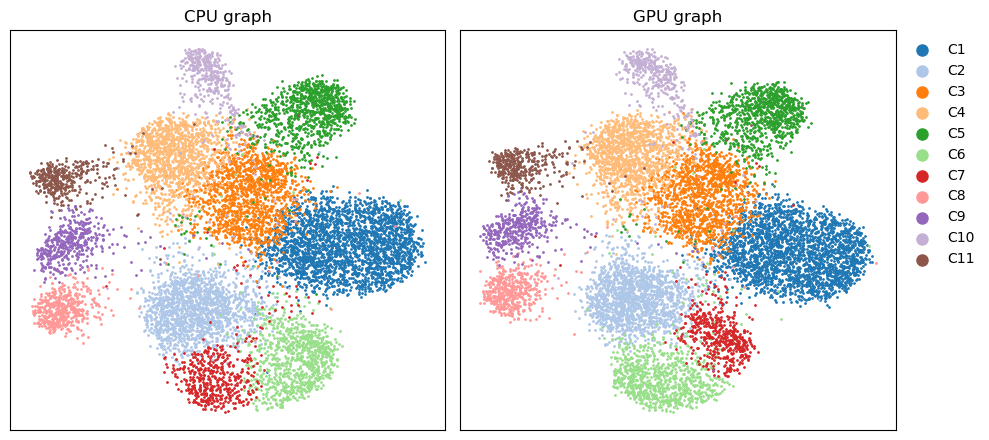

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5))
for ax, (name, g) in zip(axes, [('CPU graph', g_cpu), ('GPU graph', g_gpu)]):
    epi.tl.umap(g, random_state=1)
    xy = g.obsm['X_umap']
    for k, cl in enumerate(peaks.obs['Clusters'].cat.categories):
        m = (peaks.obs['Clusters'] == cl).to_numpy()
        ax.scatter(xy[m, 0], xy[m, 1], s=1, label=cl, color=plt.cm.tab20(k), rasterized=True)
    ax.set_title(name); ax.set_xticks([]); ax.set_yticks([])
axes[1].legend(markerscale=8, bbox_to_anchor=(1, 1), loc='upper left', frameon=False)
plt.tight_layout()

In [8]:
from sklearn.metrics import adjusted_rand_score
for g in (g_cpu, g_gpu):
    epi.tl.clusters(g, method='leiden', key_added='leiden',
                    leiden_kwargs=dict(resolution=1.2, random_state=1, flavor='igraph',
                                       n_iterations=2, directed=False))
print('ARI(Leiden on CPU graph, Leiden on GPU graph) =',
      round(adjusted_rand_score(g_cpu.obs['leiden'], g_gpu.obs['leiden']), 4))
print('ARI(Leiden on CPU graph, stored Clusters)      =',
      round(adjusted_rand_score(g_cpu.obs['leiden'], peaks.obs['Clusters']), 4))

Running Leiden clustering with igraph...


    Finished: found 12 clusters
    Added 'leiden' to adata.obs (categorical)
Running Leiden clustering with igraph...


    Finished: found 11 clusters
    Added 'leiden' to adata.obs (categorical)
ARI(Leiden on CPU graph, Leiden on GPU graph) = 0.7394
ARI(Leiden on CPU graph, stored Clusters)      = 0.7364


The ARI between the two graphs' partitions is of the same size as the ARI between Leiden runs with different seeds on one graph (0.75 on this data, `tests/parity/gpu/MANIFEST.md`, gate G11): Leiden at resolution 1.2 is that sensitive, and the self-distance difference above is enough to move it.

## chromVAR deviations

The stored motif matrix (746 JASPAR 2020 motifs) and 50 background peers per
peak. The GPU path works in cell batches and never densifies the peak matrix
on the host.

In [9]:
def chromvar(dev):
    a = ad.AnnData(peaks.X, var=peaks.var[[]].copy())
    a.varm['motif'] = peaks.varm['motif']; a.varm['bg_peaks'] = peaks.varm['bg_peaks']
    a.uns['motif_names'] = peaks.uns['motif_names']
    epi.tl.compute_deviations(a, method='analytical', verbose=False, device=dev)
    return a.obsm['motif_deviations']

z_cpu, z_gpu = run('chromVAR', chromvar)
names = np.asarray(peaks.uns['motif_names'])
r = np.array([np.corrcoef(z_cpu[:, j], z_gpu[:, j])[0, 1] for j in range(z_cpu.shape[1])
              if np.isfinite(z_cpu[:, j]).all() and z_cpu[:, j].std() > 0])
print(f'per-motif Pearson r: min {r.min():.7f}; max |dZ| {np.nanmax(np.abs(z_cpu - z_gpu)):.2e}')

chromVAR: CPU 218.1 s | GPU 10.3 s | 21.1x
per-motif Pearson r: min 1.0000000; max |dZ| 3.64e-04


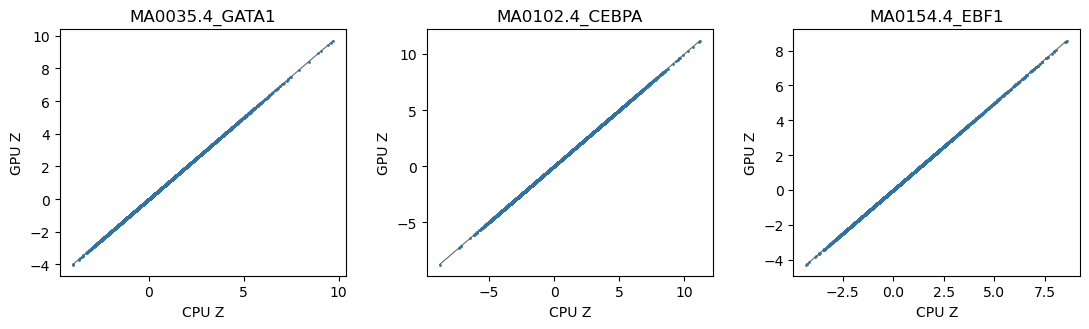

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(11, 3.4))
for ax, tf in zip(axes, ['GATA1', 'CEBPA', 'EBF1']):
    j = next(i for i, n in enumerate(names) if n.upper().endswith('_' + tf))
    ax.scatter(z_cpu[:, j], z_gpu[:, j], s=1, rasterized=True)
    lim = [np.nanmin(z_cpu[:, j]), np.nanmax(z_cpu[:, j])]
    ax.plot(lim, lim, lw=0.8, color='0.4')
    ax.set_title(names[j]); ax.set_xlabel('CPU Z'); ax.set_ylabel('GPU Z')
plt.tight_layout()

## Motif scanning

`add_motif_matrix` scans the peak sequences with MOODS on the CPU. On the GPU
it scores every window with a float32 convolution and rescores the windows
within rounding distance of the threshold exactly as MOODS does (float64,
MOODS's column order), so the hit matrices are identical. To keep the CPU half
of this notebook short we scan the first 20,000 peaks.

In [11]:
from pyjaspar import jaspardb
motifs = jaspardb(release='JASPAR2020').fetch_motifs(collection='CORE', tax_group=['vertebrates'])
sub = slice(0, 20000)


def scan(dev):
    a = ad.AnnData(sp.csr_matrix((peaks.n_obs, 20000), dtype=np.float32),
                   var=peaks.var.iloc[sub][[]].copy())
    a.uns['peak_seq'] = list(np.asarray(peaks.uns['peak_seq'])[sub])
    epi.tl.add_motif_matrix(a, genome_fasta='unused', pwms=motifs, verbose=False, device=dev)
    return a.varm['motif']

m_cpu, m_gpu = run('motif scan (20k peaks)', scan)
print(f'{m_cpu.nnz:,} hits on the CPU, {m_gpu.nnz:,} on the GPU, '
      f'{(m_cpu != m_gpu).nnz} differing entries')

motif scan (20k peaks): CPU 18.8 s | GPU 9.0 s | 2.1x
992,142 hits on the CPU, 992,142 on the GPU, 0 differing entries


## Peak-to-gene links

> **Note.** This section benchmarks the ArchR port `epi.tl.peak_to_gene` on CPU vs GPU. Epione's default enhancer–gene linker is now `epi.tl.link_peaks_to_genes` (e2g; CPU, faster than `peak_to_gene` on the same data and threads).


In [12]:
gs = ad.read_h5ad(DATA / 'heme_gene_scores.h5ad')
ann = gs.var[['chrom', 'start', 'end', 'strand']].copy()
ann.insert(0, 'gene_name', gs.var_names)
ann = ann.reset_index(drop=True)


def p2g(dev):
    return epi.tl.peak_to_gene(peaks, rna=gs, gene_annotation=ann, use_rep='X_iterative_lsi',
                               verbose=False, inplace=False, device=dev)

l_cpu, l_gpu = run('peak_to_gene', p2g)
print(f'{len(l_cpu):,} pairs; max |d correlation| '
      f'{np.abs(l_cpu.correlation.values - l_gpu.correlation.values).max():.2e}; '
      f'FDR < 0.05: CPU {(l_cpu.fdr < 0.05).sum():,}, GPU {(l_gpu.fdr < 0.05).sum():,}')

peak_to_gene: CPU 9.2 s | GPU 4.1 s | 2.2x
1,493,249 pairs; max |d correlation| 3.64e-06; FDR < 0.05: CPU 724,309, GPU 724,311


## Wall time

Measured in this notebook. The CPU uses the threads printed in the setup
cell; the GPU numbers include host-device transfers. On a GPU shared with
other jobs (as when this notebook was executed: an H100 under MPS with another
training job running) the GPU times are upper bounds.

In [13]:
t = pd.DataFrame(TIMES).pivot(index='step', columns='device', values='seconds')
t = t.loc[[s for s in dict.fromkeys(r['step'] for r in TIMES)]]
t['speed-up'] = t['CPU'] / t['GPU']
t.round(2)

device,CPU,GPU,speed-up
step,,,
lsi,23.44,4.60,5.09
iterative_lsi,57.45,14.96,3.84
neighbors,1.63,0.09,18.26
chromVAR,218.11,10.33,21.11
motif scan (20k peaks),18.77,9.01,2.08
peak_to_gene,9.16,4.08,2.25


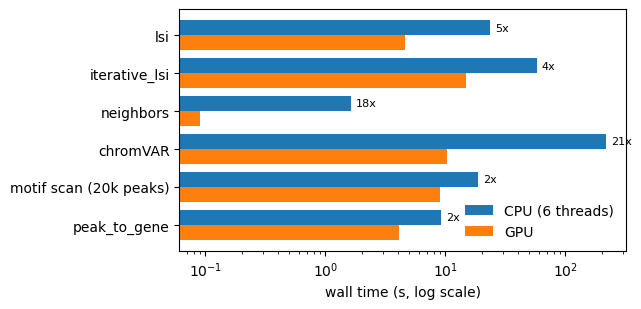

In [14]:
fig, ax = plt.subplots(figsize=(6.5, 3.2))
y = np.arange(len(t))
ax.barh(y - 0.2, t['CPU'], 0.4, label=f'CPU ({n_threads} threads)')
ax.barh(y + 0.2, t['GPU'], 0.4, label='GPU')
ax.set_yticks(y, t.index); ax.invert_yaxis(); ax.set_xscale('log')
ax.set_xlabel('wall time (s, log scale)')
for i, s in enumerate(t['speed-up']):
    ax.text(t['CPU'].iloc[i] * 1.1, i - 0.2, f'{s:.0f}x', va='center', fontsize=8)
ax.legend(frameon=False, loc='lower right')
plt.tight_layout()

## Summary

* Deterministic steps (LSI, neighbours, chromVAR, peak-to-gene) agree with
  the CPU to floating-point rounding, and the motif scan is identical.
* Iterative LSI with two or more rounds differs from the CPU by about as
  much as two CPU seeds differ from each other, because the CPU's intermediate
  clustering uses approximate neighbours.
* The pre-registered parity gates for all of these, on the full data, are in
  `tests/parity/gpu/MANIFEST.md`.

For UMAP and Leiden on the GPU, install rapids-singlecell and pass
`backend="rapids"` (see the [GPU acceleration](../../gpu.md) page):

```python
epi.pp.neighbors(adata, use_rep='X_iterative_lsi', backend='rapids')
epi.tl.umap(adata, backend='rapids')
epi.tl.clusters(adata, method='leiden', backend='rapids')
```